# 3.2-3.4 Controlled comparisons (Section 2.7)

**Figure 2** (different encoders vs repeated runs of one encoder), **Table 2** (effects on held-out-test norm_score), **Table S10a-c** (per-task controls, contrasts, S(m, d) grid), **Figures S9-S11** and the values of **Supplementary Note S3**.

Everything is recomputed from the per-molecule predictions in `../data/recompute_data/predictions/` and the archived leaderboard snapshot, with the manuscript scoring convention (Section 2.5): for each configuration the official raw metric is computed for every realization (a split, or an assignment of runs to members), the raw values are averaged, and the mean is rank-normalized once. Intervals are task-bootstrap 95% percentile intervals (2,000 resamples of the 21 tasks, seed 20261002). The code lives in `../code/followup/` (`tfcc.py`, `figs.py` and three descriptive analysis scripts). `assert` blocks check the recomputed values against the manuscript.

Analyses C and the uncertainty analysis need the TDC training/validation SMILES (for Tanimoto similarity). They are read from `$TDC_ADMET_GROUP`, else `../data/tdc_admet_group/`, else downloaded once with PyTDC into `../data/admet_group/`.

In [1]:
import os, sys, json, glob, shutil, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

HERE = os.getcwd()
REPO = os.path.abspath(os.path.join(HERE, ".."))
FOLLOW = os.path.join(REPO, "code", "followup")
sys.path.insert(0, FOLLOW)
import tfcc, figs

FIG = os.path.join(REPO, "figures"); TAB = os.path.join(REPO, "tables")
RES = os.path.join(REPO, "results", "controlled_comparisons")
for d in (FIG, TAB, RES):
    os.makedirs(d, exist_ok=True)

C = tfcc.Ctx(REPO)            # per-task test arrays for the 10 base models x 5 runs
TOL = 6e-4                    # manuscript values are rounded to 3 decimals

def check(row, est, lo=None, hi=None, wtl=None, tol=TOL):
    assert abs(row["delta"] - est) < tol, (row["contrast"], row["delta"], est)
    if lo is not None:
        assert abs(row["ci_low"] - lo) < tol and abs(row["ci_high"] - hi) < tol, (row["contrast"], row["ci_low"], row["ci_high"])
    if wtl is not None:
        assert (int(row["wins"]), int(row["ties"]), int(row["losses"])) == wtl, (row["contrast"], row["wins"], row["ties"], row["losses"])
print(len(C.TASKS), "tasks;", len(C.MODELS), "base models")

21 tasks; 10 base models


## Validation-only selection of the multi-run controls (Note S3.7)

The global validation-best model is the k = 1 row of the 1,023-subset table with the highest validation norm_score; the per-task validation-best model uses per-task validation norm_scores averaged over runs. No test labels are used.

In [2]:
P, SEL = tfcc.heterogeneity_grid(C)     # per-task score of every arm (several minutes on CPU)
sel_pool = pd.Series(SEL["task_pool"]).map(tfcc.NAMES).value_counts().to_dict()
sel_all = pd.Series(SEL["task_all"]).map(tfcc.NAMES).value_counts().to_dict()
print("validation-best, pool:", tfcc.NAMES[SEL["global_pool"]], "| all 10:", tfcc.NAMES[SEL["global_all"]])
print("per-task validation-best, pool:", sel_pool)
print("per-task validation-best, all 10:", sel_all)
assert SEL["global_pool"] == "stl_chemeleon" and SEL["global_all"] == "stl_map"
assert sel_pool == {"CheMeleon·STL": 14, "GraphMVP·STL": 3, "MoLFormer·MTL": 2, "D-MPNN·MTL": 2}
assert sel_all["CheMeleon·STL"] == 6 and sel_all["MAP·STL"] == 6 and sel_all["CheMeleon·MTL"] == 3
P.to_csv(os.path.join(RES, "heterogeneity_pertask_all_arms.csv"))

validation-best, pool: CheMeleon·STL | all 10: MAP·STL
per-task validation-best, pool: {'CheMeleon·STL': 14, 'GraphMVP·STL': 3, 'MoLFormer·MTL': 2, 'D-MPNN·MTL': 2}
per-task validation-best, all 10: {'CheMeleon·STL': 6, 'MAP·STL': 6, 'CheMeleon·MTL': 3, 'MoLFormer·MTL': 2, 'GraphMVP·STL': 2, 'MAP·MTL': 1, 'MoLFormer·STL': 1}


## Member count versus encoder heterogeneity (Section 3.2; Note S3.2)

N = S(4, 4) − S(1, 1); E_cnt = S(4, 1) − S(1, 1); E_div(m) = S(m, min(m, 4)) − S(m, 1). Heterogeneous ensembles are compared with same-encoder (and, for the "all 10" rows, same-model) multi-run ensembles of equal size.

In [3]:
CT, G = tfcc.heterogeneity_contrasts(C, P)
g = lambda lab: CT[CT.contrast == lab].iloc[0]
print(CT[["contrast", "delta", "ci_low", "ci_high", "wins", "ties", "losses"]].round(3).to_string(index=False))

S = G.set_index(["m", "d"]).S
for (m, d), v in {(1, 1): 0.552, (4, 1): 0.640, (5, 1): 0.646, (4, 4): 0.844, (5, 4): 0.846}.items():
    assert abs(S[(m, d)] - v) < TOL, ((m, d), S[(m, d)], v)
check(g("N = S(4,4) - S(1,1)"), 0.292, 0.253, 0.328, (21, 0, 0))
check(g("E_cnt = S(4,1) - S(1,1)"), 0.088, 0.066, 0.108, (19, 1, 1))
check(g("E_div(4)"), 0.204, 0.164, 0.241, (21, 0, 0))
for m, v in {2: 0.119, 3: 0.159, 5: 0.200}.items():
    check(g(f"E_div({m})"), v); assert g(f"E_div({m})").ci_low > 0
sh = g("count share E_cnt/N (descriptive)")
assert abs(sh.delta - 0.30) < 0.006 and abs(sh.ci_low - 0.23) < 0.006 and abs(sh.ci_high - 0.38) < 0.006
check(g("matched-seed heterogeneous (4) vs same-encoder, mean of 4 encoders"), 0.192, 0.154, 0.227, (20, 1, 0))
# four different encoders vs four runs (Fig. 2C circles)
check(g("m=4: heterogeneous vs same-encoder, validation-best encoder (CheMeleon·STL)"), 0.112, 0.035, 0.203, (13, 4, 4))
check(g("m=4: heterogeneous vs same-encoder, per-task validation-best encoder"), 0.094, 0.014, 0.183, (11, 6, 4))
check(g("m=4: heterogeneous vs same-model, validation-best of all 10 (MAP·STL)"), 0.081, 0.004, 0.162)
check(g("m=4: heterogeneous vs same-model, per-task validation-best of all 10"), 0.083, 0.000, 0.180)
check(g("m=4: heterogeneous vs same-encoder, per-task test-best encoder (oracle)"), -0.031, -0.060, -0.003, (3, 9, 9))
# Tetra-Fuse vs five runs (Fig. 2C diamonds; Section 3.4)
assert abs(P.TF_ms.mean() - 0.8539) < 1e-4, P.TF_ms.mean()
check(g("Tetra-Fuse vs same-encoder 5 runs, validation-best encoder (CheMeleon·STL)"), 0.124, 0.049, 0.211, (14, 4, 3))
check(g("Tetra-Fuse vs same-encoder 5 runs, per-task validation-best encoder"), 0.100, 0.024, 0.187, (12, 5, 4))
check(g("Tetra-Fuse vs same-model 5 runs, validation-best of all 10 (MAP·STL)"), 0.079, 0.017, 0.149, (10, 7, 4))
check(g("Tetra-Fuse vs same-model 5 runs, per-task validation-best of all 10"), 0.086, 0.005, 0.179, (12, 4, 5))
check(g("Tetra-Fuse vs same-model 5 runs, per-task test-best of all 10 (oracle)"), -0.078, -0.105, -0.051)
print("Section 3.2 / Note S3.2 values reproduced")

                                                                                               contrast  delta  ci_low  ci_high  wins  ties  losses
                                                 m=4: heterogeneous vs same-encoder, mean of 4 encoders  0.204   0.164    0.241  21.0   0.0     0.0
                            m=4: heterogeneous vs same-encoder, validation-best encoder (CheMeleon·STL)  0.112   0.035    0.203  13.0   4.0     4.0
                                   m=4: heterogeneous vs same-encoder, per-task validation-best encoder  0.094   0.014    0.183  11.0   6.0     4.0
                                m=4: heterogeneous vs same-encoder, per-task test-best encoder (oracle) -0.031  -0.060   -0.003   3.0   9.0     9.0
                                  m=4: heterogeneous vs same-model, validation-best of all 10 (MAP·STL)  0.081   0.004    0.162  10.0   6.0     5.0
                                   m=4: heterogeneous vs same-model, per-task validation-best of all 10  0.083  

## Figure 2. At equal member count, ensembles of different encoders outperform multi-run ensembles of one encoder.

figure2.png written


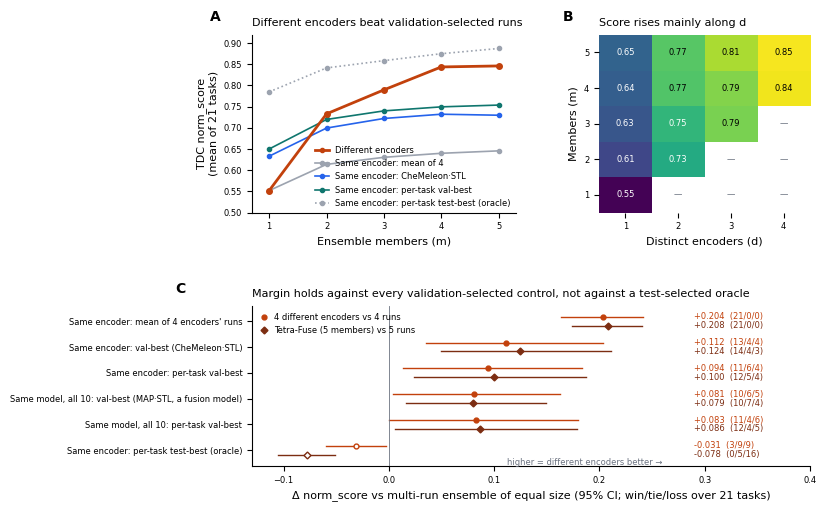

In [4]:
fig2 = figs.figure2(C, P, G)
fig2.savefig(os.path.join(FIG, "figure2.png"), dpi=300, bbox_inches="tight")
print("figure2.png written")
plt.show()

*Figure 2. At equal member count, ensembles of different encoders outperform multi-run ensembles of one encoder. The pool is the four encoder types of Tetra-Fuse (CheMeleon·STL, D-MPNN·MTL, MoLFormer·MTL, GraphMVP·STL), each with five independently trained runs. Every configuration is scored by averaging the raw metric over its realizations and normalizing once (Section 2.5). (A) Mean norm_score over 21 tasks versus the number of averaged members m. The heterogeneous series uses min(m, 4) distinct encoders. The same-encoder series show four multi-run controls: the mean over the four encoders, the validation-best encoder (CheMeleon·STL), the per-task validation-best encoder, and the per-task test-best encoder (dotted; a non-deployable oracle). (B) Mean norm_score for every combination of member count m and number of distinct encoders d. (C) Differences between heterogeneous ensembles and same-encoder ensembles of equal size, with task-bootstrap 95% intervals and per-task win/tie/loss counts. Circles: four different encoders versus four runs. Diamonds: Tetra-Fuse (five members, including MAP·STL) versus five runs. Rows labelled "all 10" are same-model multi-run controls drawn from all base models; they can be MAP, which is itself a fusion of three encoders, and are therefore not strictly same-encoder controls. Open symbols mark the test-label oracle.*

## Table S10a-c (XLSX sheets)

(a) per-task held-out-test norm_score of heterogeneous ensembles and equal-sized multi-run controls; (b) all controlled contrasts; (c) the S(m, d) grid.

In [5]:
S10a, S10b, S10c = tfcc.table_s10(P, CT, G)
S10a.to_csv(os.path.join(TAB, "tableS10a_pertask_controls.csv"), index=False)
S10b.to_csv(os.path.join(TAB, "tableS10b_contrasts.csv"), index=False)
S10c.to_csv(os.path.join(TAB, "tableS10c_grid.csv"), index=False)
mean_row = S10a.set_index("Task").loc["Mean"]
assert abs(mean_row["Het. 4"] - 0.844) < TOL and abs(mean_row["Het. 4, matched-seed"] - 0.832) < TOL
assert abs(mean_row["Tetra-Fuse"] - 0.854) < TOL and abs(mean_row["MAP·STL ×5"] - 0.774) < TOL
S10a.tail(3)

,Task,Metric,Het. 4,"Het. 4, matched-seed","Same-enc. 4, mean",CheMeleon·STL ×4,Per-task val-best ×4,Per-task test-best ×4 (oracle),Tetra-Fuse,CheMeleon·STL ×5,Per-task val-best ×5,MAP·STL ×5,Per-task val-best (all 10) ×5,Per-task test-best (all 10) ×5 (oracle),Val-best encoder (pool),Val-best model (all 10)
19,Clearance_Microsome_AZ,Spearman,0.900,0.900,0.712,0.750,0.75,0.900,0.950,0.75,0.750,0.750,0.750,1.000,CheMeleon·STL,CheMeleon·STL
20,LD50_Zhu,MAE,0.818,0.773,0.466,1.000,1.00,1.000,0.818,1.00,1.000,1.000,1.000,1.000,CheMeleon·STL,MAP·STL
21,Mean,,0.844,0.832,0.640,0.732,0.75,0.875,0.854,0.73,0.754,0.774,0.767,0.932,,


## Secondary pools with the training paradigm fixed (Note S3.2)

The primary pool takes the stronger paradigm variant of each encoder (CheMeleon·STL, D-MPNN·MTL, MoLFormer·MTL, GraphMVP·STL). Here the same analysis is repeated with all four encoders under STL only and under MTL only. The rows are appended to Table S10b.

In [6]:
SEC = {"STL-only": ["stl_chemeleon", "stl_dmpnn", "stl_molformer", "stl_graphmvp"],
       "MTL-only": ["mtl_chemeleon", "mtl_dmpnn", "mtl_molformer", "mtl_graphmvp"]}
sec_rows = []
for name, pool in SEC.items():
    Pp, Sp = tfcc.heterogeneity_grid(C, pool)          # several minutes per pool
    vb = tfcc.NAMES[Sp["global_pool"]]
    cc = lambda a, b, lab: dict(C.contrast(Pp[a], Pp[b], lab), pool=name)
    sec_rows += [cc(f"Het_{m}_{min(m, 4)}", f"Het_{m}_1", f"E_div({m})") for m in range(2, 6)]
    sec_rows += [cc("Het_4_1", "Het_1_1", "E_cnt = S(4,1) - S(1,1)"), cc("Het_4_4", "Het_1_1", "N = S(4,4) - S(1,1)"),
                 cc("Het_4_4", "HomMean_4", "m=4: heterogeneous vs same-encoder, mean of 4 encoders"),
                 cc("Het_4_4", "HomGlobalPool_4", f"m=4: heterogeneous vs same-encoder, validation-best encoder ({vb})"),
                 cc("Het_4_4", "HomTaskValPool_4", "m=4: heterogeneous vs same-encoder, per-task validation-best encoder"),
                 cc("Het_4_4", "HomTaskTestPool_4", "m=4: heterogeneous vs same-encoder, per-task test-best encoder (oracle)")]
SEC_CT = pd.DataFrame(sec_rows)
gs = lambda pool, lab: SEC_CT[(SEC_CT.pool == pool) & (SEC_CT.contrast.str.startswith(lab))].iloc[0]
check(gs("STL-only", "E_div(4)"), 0.159, 0.113, 0.205, (20, 0, 1))
check(gs("MTL-only", "E_div(4)"), 0.127, 0.095, 0.158, (20, 0, 1))
check(gs("STL-only", "E_cnt"), 0.090); check(gs("MTL-only", "E_cnt"), 0.108)
check(gs("STL-only", "m=4: heterogeneous vs same-encoder, validation-best"), -0.053, -0.119, 0.021, (3, 6, 12))
check(gs("MTL-only", "m=4: heterogeneous vs same-encoder, validation-best"), 0.029, -0.017, 0.074, (7, 9, 5))
S10b_all = pd.concat([S10b.assign(pool="primary (Tetra-Fuse encoder types)"),
                      SEC_CT[["contrast", "delta", "ci_low", "ci_high", "wins", "ties", "losses", "pool"]].round(6)], ignore_index=True)
S10b_all = S10b_all[["pool", "contrast", "delta", "ci_low", "ci_high", "wins", "ties", "losses"]]
S10b_all.to_csv(os.path.join(TAB, "tableS10b_contrasts.csv"), index=False)
SEC_CT[["pool", "contrast", "delta", "ci_low", "ci_high", "wins", "ties", "losses"]].round(3)

,pool,contrast,delta,ci_low,ci_high,wins,ties,losses
0,STL-only,E_div(2),0.092,0.063,0.122,20,0,1
1,STL-only,E_div(3),0.134,0.096,0.175,20,0,1
2,STL-only,E_div(4),0.159,0.113,0.205,20,0,1
3,STL-only,E_div(5),0.157,0.111,0.203,20,0,1
4,STL-only,"E_cnt = S(4,1) - S(1,1)",0.090,0.067,0.116,20,1,0
5,STL-only,"N = S(4,4) - S(1,1)",0.248,0.194,0.300,21,0,0
6,STL-only,"m=4: heterogeneous vs same-encoder, mean of 4 ...",0.159,0.113,0.205,20,0,1
7,STL-only,"m=4: heterogeneous vs same-encoder, validation...",-0.053,-0.119,0.021,3,6,12
8,STL-only,"m=4: heterogeneous vs same-encoder, per-task v...",0.002,-0.070,0.077,5,8,8
9,STL-only,"m=4: heterogeneous vs same-encoder, per-task t...",-0.072,-0.130,-0.008,2,6,13


## Fusion level at matched member count (Section 3.3; Note S3.5)

MAP (one model; 3 encoder forward passes per prediction), Late-3 (uniform mean of MAP's three encoders; 3), MAP×3 (9), MAP×5 (15) and Tetra-Fuse (7). Figure 3 is drawn in `32_fusion_comparison.ipynb` from the same function.

In [7]:
FUS, FUS_C, FUS_COST = tfcc.fusion_level(C)
f = lambda lab: FUS_C[FUS_C.contrast == lab].iloc[0]
print(FUS.mean().round(3).to_dict())
print(FUS_C[["contrast", "delta", "ci_low", "ci_high", "wins", "ties", "losses"]].round(3).to_string(index=False))
for k, v in {"stl_MAP1": 0.604, "stl_Late3": 0.723, "stl_MAP3": 0.744, "stl_MAP5": 0.774,
             "mtl_MAP1": 0.617, "mtl_Late3": 0.753, "mtl_MAP3": 0.735, "mtl_MAP5": 0.762}.items():
    assert abs(FUS[k].mean() - v) < TOL, (k, FUS[k].mean(), v)
check(f("STL: Late-3 vs one MAP model (unmatched)"), 0.119, 0.056, 0.177)
check(f("MTL: Late-3 vs one MAP model (unmatched)"), 0.136, 0.085, 0.190)
check(f("STL: MAP x3 vs one MAP model (ensembling)"), 0.139, 0.096, 0.185)
check(f("STL: Late-3 vs MAP x3 (matched)"), -0.020, -0.074, 0.034)
check(f("MTL: Late-3 vs MAP x3 (matched)"), 0.018, -0.017, 0.056)
check(f("Tetra-Fuse vs MAP·STL x5"), 0.079, 0.017, 0.149, (10, 7, 4))
FUS.round(4).to_csv(os.path.join(RES, "fusion_level_pertask.csv"))
FUS_C.round(4).to_csv(os.path.join(RES, "fusion_level_contrasts.csv"), index=False)
FUS_COST.to_csv(os.path.join(RES, "fusion_level_forward_passes.csv"), index=False)
FUS_COST

{'stl_MAP1': 0.604, 'stl_Late3': 0.723, 'stl_MAP3': 0.744, 'stl_MAP5': 0.774, 'mtl_MAP1': 0.617, 'mtl_Late3': 0.753, 'mtl_MAP3': 0.735, 'mtl_MAP5': 0.762, 'TF': 0.854}
                                 contrast  delta  ci_low  ci_high  wins  ties  losses
 STL: Late-3 vs one MAP model (unmatched)  0.119   0.056    0.177    15     4       2
STL: MAP x3 vs one MAP model (ensembling)  0.139   0.096    0.185    18     3       0
          STL: Late-3 vs MAP x3 (matched) -0.020  -0.074    0.034     6     6       9
 MTL: Late-3 vs one MAP model (unmatched)  0.135   0.085    0.190    17     4       0
MTL: MAP x3 vs one MAP model (ensembling)  0.118   0.078    0.161    17     4       0
          MTL: Late-3 vs MAP x3 (matched)  0.018  -0.017    0.056     6    10       5
                 Tetra-Fuse vs MAP·STL x5  0.079   0.017    0.149    10     7       4


,arm,members,encoder_forward_passes
0,MAP (1 model),1,3
1,Late-3,3,3
2,MAP x3,3,9
3,MAP x5,5,15
4,Tetra-Fuse,5,7


## Averaging over runs (Section 3.4)

Seed-averaged minus matched-seed held-out-test norm_score, from the 1,023-subset table.

In [8]:
K1, SA = tfcc.seed_averaging(C)
print({k: round(v, 4) for k, v in SA.items()})
assert abs(SA["single_mean_gain"] - 0.116) < TOL and abs(SA["single_min"] - 0.079) < TOL and abs(SA["single_max"] - 0.187) < TOL
assert abs(SA["tf_matched"] - 0.854) < TOL and abs(SA["tf_seed_avg"] - 0.897) < TOL and abs(SA["tf_gain"] - 0.043) < TOL
K1.round(4).to_csv(os.path.join(RES, "seed_averaging_single_models.csv"), index=False)

{'tf_matched': 0.8539, 'tf_seed_avg': 0.8971, 'tf_gain': 0.0432, 'single_mean_gain': 0.1164, 'single_min': 0.0789, 'single_max': 0.1867}


## Table 2. Effects on held-out-test norm_score (21 TDC ADMET tasks; matched-seed unless noted).

In [9]:
T3 = tfcc.table3(CT, FUS_C, SA)
T3.to_csv(os.path.join(TAB, "table2_effects.csv"), index=False)
assert T3.iloc[0, 2] == "+0.088 (0.066 to 0.108)" and T3.iloc[4, 2] == "\u22120.031 (\u22120.060 to \u22120.003)"
T3

,Effect,Comparison (what is held fixed),Delta norm_score (95% CI),W/T/L
0,Adding runs of one encoder,"1 → 4 runs, mean of the four pool encoders",+0.088 (0.066 to 0.108),19/1/1
1,"Encoder heterogeneity, average control",4 members; 4 encoders vs 4 runs of one encoder...,+0.204 (0.164 to 0.241),21/0/0
2,"Encoder heterogeneity, strongest validation-se...",4 members; vs 4 runs of the validation-best en...,+0.112 (0.035 to 0.203),13/4/4
3,,4 members; vs 4 runs of the per-task validatio...,+0.094 (0.014 to 0.183),11/6/4
4,"Encoder heterogeneity, test-label oracle (desc...",4 members; vs 4 runs of the per-task test-best...,−0.031 (−0.060 to −0.003),3/9/9
5,"Fusion level, unmatched","Late-3 (3 members) vs one MAP model, STL",+0.119 (0.056 to 0.177),–
6,Ensembling the fusion model,"MAP×3 vs one MAP model, STL",+0.139 (0.096 to 0.185),–
7,"Fusion level, matched","Late-3 vs MAP×3, STL / MTL",−0.020 (−0.074 to 0.034) / +0.018 (−0.017 to 0...,–
8,Averaging over runs,"Seed-averaged minus matched-seed, mean of 10 b...",+0.116 (range 0.079 to 0.187) / +0.043,–


*Table 2. Effects on held-out-test norm_score (21 TDC ADMET tasks; matched-seed unless noted). Intervals are task-bootstrap 95% percentile intervals; W/T/L are per-task wins, ties and losses.*

## Error decomposition, similarity strata and uncertainty (Note S3.3, S3.4, S3.6; Figures S9-S11)

These three descriptive analyses work on per-molecule losses rather than on norm_score. Each script writes its tables to `../results/controlled_comparisons/<name>/`; the figures are copied to `../figures/figureS7.png`-`figureS9.png`.

In [10]:
def tdc_admet_dir():
    for d in (os.environ.get("TDC_ADMET_GROUP"), os.path.join(REPO, "data", "tdc_admet_group"),
              os.path.join(REPO, "data", "admet_group")):
        if d and os.path.isfile(os.path.join(d, "caco2_wang", "train_val.csv")):
            return d
    from tdc.benchmark_group import admet_group          # one-time download (~50 MB)
    admet_group(path=os.path.join(REPO, "data"))
    return os.path.join(REPO, "data", "admet_group")

ADMET = tdc_admet_dir(); print("TDC admet_group:", ADMET)
env = {**os.environ, "TDC_ADMET_GROUP": ADMET, "MPLBACKEND": "Agg"}
RUNS = [("analysis_B_decomposition.py", "B_decomposition", "B_decomposition_figure.png", "figureS7.png"),
        ("analysis_C_similarity.py", "C_similarity", "fig_C_distance_gain.png", "figureS8.png"),
        ("analysis_2_uncertainty.py", "uncertainty", "fig_A3_uncertainty.png", "figureS9.png")]
for script, sub, src_png, dst_png in RUNS:
    out = os.path.join(RES, sub)
    r = subprocess.run([sys.executable, os.path.join(FOLLOW, script), REPO, out], cwd=FOLLOW, env=env,
                       capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-3000:]
    shutil.copy(os.path.join(out, src_png), os.path.join(FIG, dst_png))
    print(f"{script}: ok -> figures/{dst_png}")

TDC admet_group: /nas/tk_ahn/ADMET-MTL/JCIM/Tetra-Fuse/data/tdc_admet_group


analysis_B_decomposition.py: ok -> figures/figureS7.png


analysis_C_similarity.py: ok -> figures/figureS8.png


analysis_2_uncertainty.py: ok -> figures/figureS9.png


In [11]:
B = pd.read_csv(os.path.join(RES, "B_decomposition", "B_summary_estimates.csv"))
Bp = B[B.analysis == "primary"].set_index("estimand")
for est, (v, lo, hi) in {"task_mean_S_minus_O": (0.036, 0.015, 0.064), "task_mean_S": (0.032, 0.017, 0.052),
                         "task_mean_O": (-0.004, -0.018, 0.007)}.items():
    r = Bp.loc[est]; assert abs(r.estimate - v) < TOL and abs(r.ci_low - lo) < TOL and abs(r.ci_high - hi) < TOL, (est, r.estimate, r.ci_low, r.ci_high)
Cs = pd.read_csv(os.path.join(RES, "C_similarity", "C_summary.csv"))
r = Cs[(Cs.estimand == "mean_slope") & (Cs.contrast == "primary_G_stl_map")].iloc[0]
assert abs(r.estimate - 0.0006) < 5e-5 and int(r.n_pos) == 13, (r.estimate, r.n_pos)
U = pd.read_csv(os.path.join(RES, "uncertainty", "A3_summary.csv"))
r = U[U.estimand.str.startswith("VERDICT_")].iloc[0]
assert abs(r.estimate - 0.037) < TOL and abs(r.ci_low - 0.008) < TOL and abs(r.ci_high - 0.069) < TOL, (r.estimate, r.ci_low, r.ci_high)
print("Note S3.3 (B), S3.4 (C) and S3.6 (uncertainty) primary values reproduced")
pd.concat([B.assign(analysis_file="B"), Cs.assign(analysis_file="C"), U.assign(analysis_file="uncertainty")],
          ignore_index=True).to_csv(os.path.join(RES, "noteS3_descriptive_summaries.csv"), index=False)

Note S3.3 (B), S3.4 (C) and S3.6 (uncertainty) primary values reproduced


In [12]:
# Note S3.3: error decomposition by task type (classification: Brier; regression: variance-scaled MSE)
Bpt = pd.read_csv(os.path.join(RES, "B_decomposition", "B_pertask_decomposition.csv"))
prim = Bpt[(Bpt.analysis == "primary") & (Bpt.track == "matched")]
BYT = prim.groupby("type")[["T", "S", "O", "S_minus_O"]].mean().assign(n_tasks=prim.groupby("type").size())
assert BYT.loc["classification", "n_tasks"] == 12 and BYT.loc["regression", "n_tasks"] == 9
assert abs(BYT.loc["classification", "S"] - 0.0137) < 5e-4 and abs(BYT.loc["classification", "O"] - 0.0011) < 5e-4
assert abs(BYT.loc["regression", "S"] - 0.0561) < 5e-4 and abs(BYT.loc["regression", "O"] + 0.0108) < 5e-4
BYT.round(4).to_csv(os.path.join(RES, "B_decomposition", "B_by_task_type.csv"))
BYT.round(4)

,T,S,O,S_minus_O,n_tasks
type,,,,,
classification,0.0147,0.0137,0.0011,0.0126,12
regression,0.0453,0.0561,-0.0108,0.0669,9
